### CNN 및 DROPOUT

## STL-10 Dataset
: 자연 및 인공 사물 이미지를 10개 클래스로 분류하는 이미지 데이터셋

- 학습데이터 : 5,000장 (라벨 데이터)
- 테스트 데이터 : 8,000장
- 비라벨 학습데이터 : 100,000장
- 원본 이미지 크기 : 96 × 96 (컬러 이미지)
- 입력 데이터: RGB 이미지 (64 × 64로 크기 변경)
- 입력 특징 수: 3 × 64 × 64 = 3,072
- 출력 클래스: 10개
- 다운로드 : `split="train"`과 `split="test"`를 구분하여 다운로드
- 모델은 CNN, CNN_deep, CNN_drop (p=0.3), CNN_deep_drop (p=0.3) 4가지를 정의하여 사용

| 클래스 이름 | 의미 |
|:---:|:---|
| `airplane` | 비행기 |
| `bird` | 새 |
| `car` | 자동차 |
| `cat` | 고양이 |
| `deer` | 사슴 |
| `dog` | 개 |
| `horse` | 말 |
| `monkey` | 원숭이 |
| `ship` | 선박 |
| `truck` | 트럭 |

LR = 1e-3<br>
EPOCH = 30<br>
**test_DS.class_to_idx**는 기본제공되지 않음

1. 문제 1
- train, test데이터 모두 transforms는 사이즈 64 x 64 적용

2. 문제 2
- train 데이터의 transforms는
    - 사이즈 64 x 64 적용
    - 이미지의 좌우 반전을 50%의 확률로 적용
    - 입력 이미지의 상하좌우에 4픽셀씩 패딩을 추가한 후, 64×64 크기를 무작위로 잘라내기 (transforms.RandomCrop(64, padding=4))
    - Normalize((0.4467, 0.4398, 0.4066),(0.2603, 0.2566, 0.2713)) 적용

- test 데이터의 transforms는
    - 사이즈 64 x 64 적용
    - Normalize((0.4467, 0.4398, 0.4066),(0.2603, 0.2566, 0.2713)) 적용

**실행시 문제1과 문제2는 하나씩 선택하여 실행**

In [23]:
from multiclass_functions import *
import torch
from torch import nn, optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt
import os
os.makedirs('results', exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE)

cpu


In [24]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 10
criterion = nn.CrossEntropyLoss()
new_model_train = True
model_type = 'CNN_deep'
dataset = 'STL10'
save_model_path = f'results/{model_type}_{dataset}.pt'

In [25]:
# transform = transforms.Compose([
#     transforms.Resize(size=(64,64)),
#     transforms.ToTensor()
# ])
# train_DS = datasets.STL10(root='data', split='train', download=True, transform=transform)
# test_DS = datasets.STL10(root='data', split='test', download=True, transform=transform)
# train_DL = DataLoader(train_DS, batch_size=BATCH_SIZE, shuffle=True)
# test_DL = DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=False)

In [26]:
transform_train = transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(64, padding=4),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4467, 0.4398, 0.4066),
        (0.2603, 0.2566, 0.2713)
    )
])
transform_test = transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4467, 0.4398, 0.4066),
        (0.2603, 0.2566, 0.2713)
    )
])
train_DS = datasets.STL10(root='data', split='train', download=True, transform=transform_train)
test_DS = datasets.STL10(root='data', split='test', download=True, transform=transform_test)
train_DL = DataLoader(train_DS, batch_size=BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=False)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.7160968..1.0828024].


Text(0.5, 1.0, 'Label: deer')

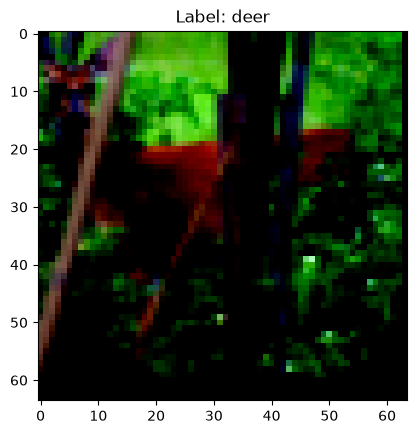

In [27]:
x_batch, y_batch = next(iter(train_DL))

plt.imshow(x_batch[0].permute(1, 2, 0))
plt.title(f"Label: {train_DS.classes[y_batch[0].item()]}")


In [28]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Sequential(nn.Conv2d(3,8,3, padding=1),
                                   nn.BatchNorm2d(8),
                                   nn.ReLU())
        self.Maxpool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Sequential(nn.Conv2d(8,16,3, padding=1),
                                   nn.BatchNorm2d(16),
                                   nn.ReLU())
        self.Maxpool2 = nn.MaxPool2d(2)
        self.conv3 = nn.Sequential(nn.Conv2d(16,32,3, padding=1),
                                   nn.BatchNorm2d(32),
                                   nn.ReLU())
        self.Maxpool3 = nn.MaxPool2d(2)
        self.fc = nn.Linear(32*8*8,10)

    def forward(self, x):
        x = self.conv1(x)
        x = self.Maxpool1(x)
        x = self.conv2(x)
        x = self.Maxpool2(x)
        x = self.conv3(x)
        x = self.Maxpool3(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x


class CNN_deep(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv_block1 = nn.Sequential(nn.Conv2d(3,32,3,padding=1),
                                         nn.BatchNorm2d(32),
                                         nn.ReLU(),
                                         nn.Conv2d(32,32,3,padding=1),
                                         nn.BatchNorm2d(32),
                                         nn.ReLU())
        self.Maxpool1 = nn.MaxPool2d(2)

        self.conv_block2 = nn.Sequential(nn.Conv2d(32,64,3,padding=1),
                                         nn.BatchNorm2d(64),
                                         nn.ReLU(),
                                         nn.Conv2d(64,64,3,padding=1),
                                         nn.BatchNorm2d(64),
                                         nn.ReLU(),
                                         nn.Conv2d(64,64,3,padding=1),
                                         nn.BatchNorm2d(64),
                                         nn.ReLU())
        self.Maxpool2 = nn.MaxPool2d(2)

        self.conv_block3 = nn.Sequential(nn.Conv2d(64,128,3,padding=1),
                                         nn.BatchNorm2d(128),
                                         nn.ReLU(),
                                         nn.Conv2d(128,128,3,padding=1),
                                         nn.BatchNorm2d(128),
                                         nn.ReLU(),
                                         nn.Conv2d(128,128,3,padding=1),
                                         nn.BatchNorm2d(128),
                                         nn.ReLU())
        self.Maxpool3 = nn.MaxPool2d(2)

        self.classifier = nn.Sequential(nn.Linear(128*8*8,512),
                                        nn.ReLU(),
                                        nn.Linear(512,10))

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.Maxpool1(x)
        x = self.conv_block2(x)
        x = self.Maxpool2(x)
        x = self.conv_block3(x)
        x = self.Maxpool3(x)
        x = torch.flatten(x, start_dim=1)
        x = self.classifier(x)
        return x

class CNN_deep_drop(CNN_deep):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.classifier = nn.Sequential(nn.Linear(128*8*8, 512),
                                        nn.ReLU(),
                                        nn.Dropout(0.3),
                                        nn.Linear(512, 10))

In [29]:
model = globals()[model_type]().to(DEVICE)

Epoch : 1, train loss : 2.323
--------------------
Epoch : 2, train loss : 1.693
--------------------
Epoch : 3, train loss : 1.542
--------------------
Epoch : 4, train loss : 1.466
--------------------
Epoch : 5, train loss : 1.389
--------------------
Epoch : 6, train loss : 1.337
--------------------
Epoch : 7, train loss : 1.295
--------------------
Epoch : 8, train loss : 1.243
--------------------
Epoch : 9, train loss : 1.183
--------------------
Epoch : 10, train loss : 1.130
--------------------


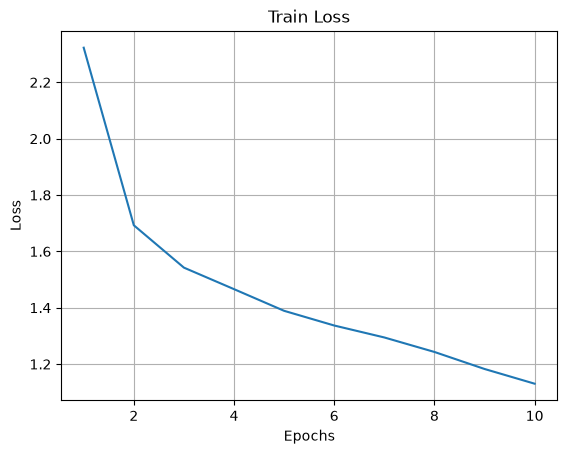

In [30]:
if new_model_train:
    optimizer = optim.Adam(model.parameters(), lr=LR)
    loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

    torch.save(model, save_model_path)

    plt.figure()
    plt.plot(range(1, EPOCH+1), loss_history)
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.title("Train Loss")
    plt.grid()

In [31]:
load_model = torch.load(save_model_path, map_location=DEVICE, weights_only=False)

In [32]:
Accuracy(load_model, test_DL, 'Test')
Accuracy(load_model, train_DL, 'Train')

Test Accuracy : 4534 / 8000 (56.7 %)
Train Accuracy : 2965 / 5000 (59.3 %)


59.3

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.459982..2.065362].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.1586705..1.9147061].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.2490641..1.204325].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.4147854..1.7489849].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.6558344..1.9599028].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.7160968..2.1525989].


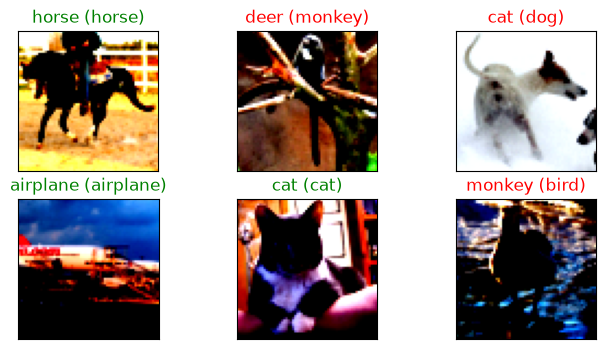

In [33]:
Test_plot(load_model, test_DL)

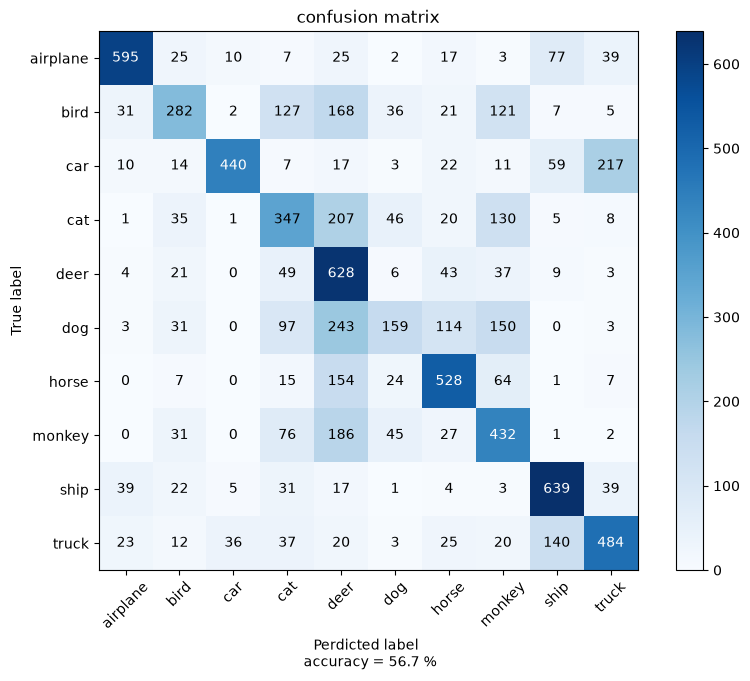

In [34]:
confusion = get_conf(load_model, test_DL)
plot_confusion_matrix(confusion, test_DS.classes)
plt.xticks(rotation=45);